# House Price Prediction - Data Visualization

This notebook creates and saves six visualizations of the original housing data. It reads the CSV without changing it and does not train a model.

## Load the dataset

The path is relative to this notebook. We inspect the actual columns and select the price, area, numeric, and area-preference features from the loaded data.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

data_path = Path("../dataset/Housing.csv")
output_dir = Path("../outputs/visualizations")
output_dir.mkdir(parents=True, exist_ok=True)

houses = pd.read_csv(data_path)
print(f"Loaded {data_path.name}: {houses.shape[0]} rows and {houses.shape[1]} columns")
print("Actual columns:", houses.columns.tolist())

column_lookup = {column.strip().lower(): column for column in houses.columns}
price_column = column_lookup.get("price")
area_column = column_lookup.get("area")
preferred_area_column = column_lookup.get("prefarea")
if price_column is None or area_column is None:
    raise KeyError("The dataset must contain the observed price and area columns for these plots.")
if preferred_area_column is None:
    raise KeyError("The dataset has no preferred-area column for the area-related category chart.")

numeric_columns = houses.select_dtypes(include=np.number).columns.tolist()
selected_numeric_columns = [
    column for column in [price_column, area_column, "bedrooms", "bathrooms"]
    if column in numeric_columns
]
if len(selected_numeric_columns) < 2:
    raise ValueError("At least two numeric columns are needed for the requested plots.")

sns.set_theme(style="whitegrid")
plot_files = []
print("Price column:", price_column)
print("Area column:", area_column)
print("Numeric columns:", numeric_columns)
print("Preferred-area category:", preferred_area_column)

Loaded Housing.csv: 545 rows and 13 columns
Actual columns: ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']
Price column: price
Area column: area
Numeric columns: ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'parking']
Preferred-area category: prefarea


## A. House price distribution - histogram

The histogram shows how house prices are distributed. The optional density curve helps reveal the overall shape; a long upper tail indicates that a smaller number of homes have substantially higher prices.

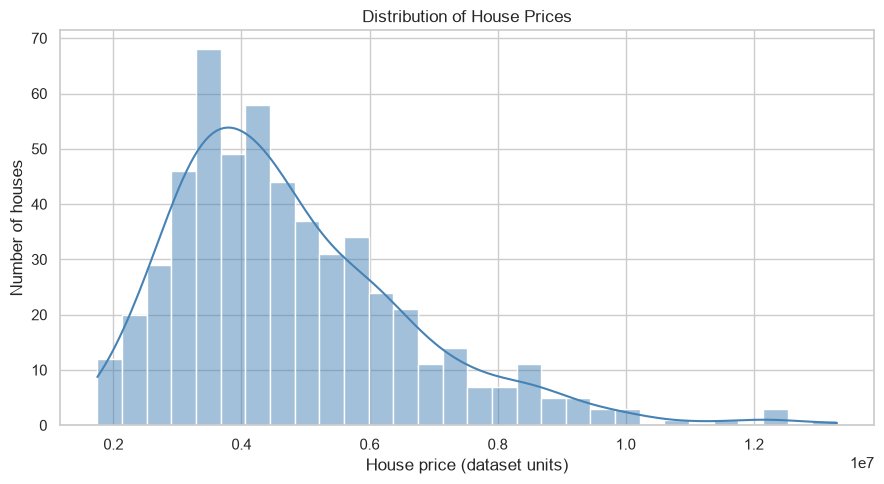

Saved: ..\outputs\visualizations\house_price_distribution_histogram.png


In [2]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=houses, x=price_column, bins=30, kde=True, color="steelblue", ax=ax)
ax.set_title("Distribution of House Prices")
ax.set_xlabel("House price (dataset units)")
ax.set_ylabel("Number of houses")
fig.tight_layout()

histogram_path = output_dir / "house_price_distribution_histogram.png"
fig.savefig(histogram_path, dpi=150, bbox_inches="tight")
plot_files.append(histogram_path)
plt.show()
plt.close(fig)
print("Saved:", histogram_path)

## B. House area and price - scatter plot

Each point represents one house. This plot uses the dataset's observed `area` and `price` columns to show whether larger homes tend to have higher prices and how much the observations vary.

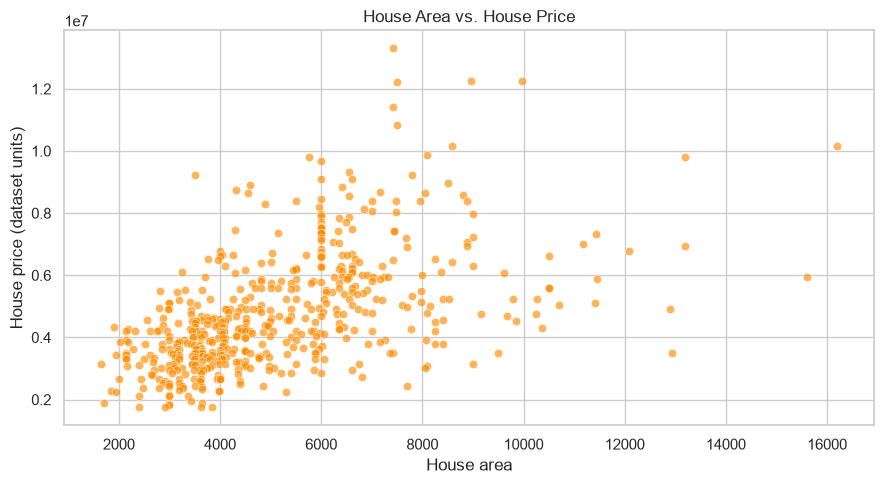

Saved: ..\outputs\visualizations\house_area_vs_price_scatter.png
Correlation between area and price: 0.54


In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=houses, x=area_column, y=price_column, alpha=0.65, color="darkorange", ax=ax)
ax.set_title("House Area vs. House Price")
ax.set_xlabel("House area")
ax.set_ylabel("House price (dataset units)")
fig.tight_layout()

scatter_path = output_dir / "house_area_vs_price_scatter.png"
fig.savefig(scatter_path, dpi=150, bbox_inches="tight")
plot_files.append(scatter_path)
plt.show()
plt.close(fig)
print("Saved:", scatter_path)
print(f"Correlation between {area_column} and {price_column}: {houses[area_column].corr(houses[price_column]):.2f}")

## C. Numerical feature correlations - heatmap

The heatmap compares pairwise correlations among all numeric columns. Values closer to 1 indicate a stronger positive linear association, values closer to -1 a stronger negative association, and values near 0 a weaker linear association. Correlation does not prove causation.

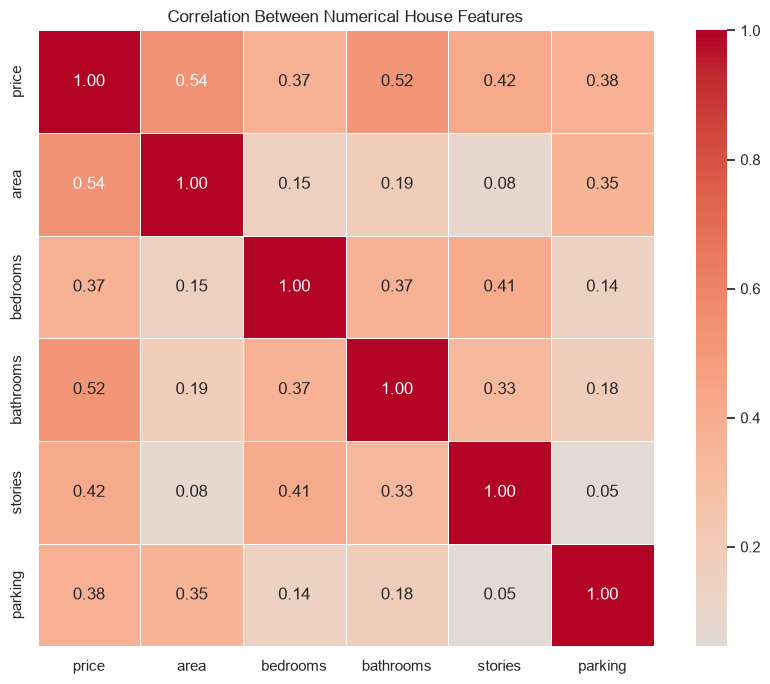

Saved: ..\outputs\visualizations\numeric_features_correlation_heatmap.png


In [4]:
numeric_correlation = houses[numeric_columns].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    numeric_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
    ax=ax,
)
ax.set_title("Correlation Between Numerical House Features")
fig.tight_layout()

heatmap_path = output_dir / "numeric_features_correlation_heatmap.png"
fig.savefig(heatmap_path, dpi=150, bbox_inches="tight")
plot_files.append(heatmap_path)
plt.show()
plt.close(fig)
print("Saved:", heatmap_path)

## D. House price spread and potential outliers - box plot

The box shows the median and middle 50% of prices; points beyond the whiskers are potential outliers, not necessarily errors. The calculation below reports values outside the standard 1.5 x IQR fences for context.

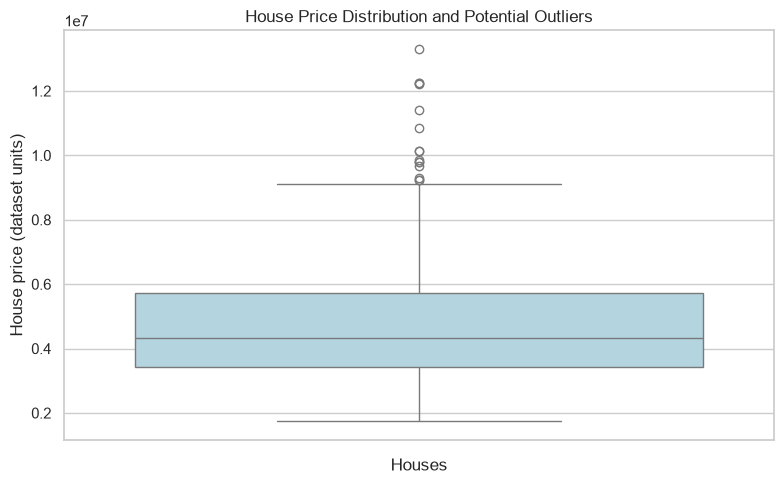

Saved: ..\outputs\visualizations\house_price_boxplot.png
Potential price outliers by the 1.5 x IQR rule: 15
IQR fences: -35,000 to 9,205,000


In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=houses, y=price_column, color="lightblue", ax=ax)
ax.set_title("House Price Distribution and Potential Outliers")
ax.set_xlabel("Houses")
ax.set_ylabel("House price (dataset units)")
fig.tight_layout()

boxplot_path = output_dir / "house_price_boxplot.png"
fig.savefig(boxplot_path, dpi=150, bbox_inches="tight")
plot_files.append(boxplot_path)
plt.show()
plt.close(fig)

first_quartile = houses[price_column].quantile(0.25)
third_quartile = houses[price_column].quantile(0.75)
interquartile_range = third_quartile - first_quartile
lower_fence = first_quartile - 1.5 * interquartile_range
upper_fence = third_quartile + 1.5 * interquartile_range
potential_outliers = houses.loc[
    (houses[price_column] < lower_fence) | (houses[price_column] > upper_fence),
    price_column,
]
print("Saved:", boxplot_path)
print(f"Potential price outliers by the 1.5 x IQR rule: {len(potential_outliers)}")
print(f"IQR fences: {lower_fence:,.0f} to {upper_fence:,.0f}")

## E. Average price by preferred-area category - bar chart

The dataset has no specific location column. `prefarea` (preferred area: yes/no) is the closest area-related category available, so this chart compares mean prices between its observed groups. It should not be interpreted as a comparison between named locations.

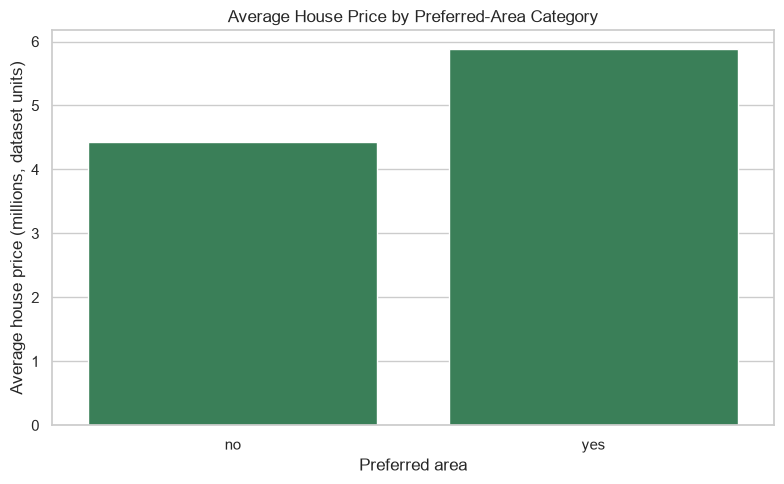

Saved: ..\outputs\visualizations\average_price_by_preferred_area.png


,prefarea,average_price,average_price_millions
0,no,4.425299e+06,4.425299
1,yes,5.879046e+06,5.879046


In [6]:
average_price_by_area = (
    houses.groupby(preferred_area_column, as_index=False)[price_column]
    .mean()
    .rename(columns={price_column: "average_price"})
)
average_price_by_area["average_price_millions"] = average_price_by_area["average_price"] / 1_000_000

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=average_price_by_area,
    x=preferred_area_column,
    y="average_price_millions",
    color="seagreen",
    ax=ax,
)
ax.set_title("Average House Price by Preferred-Area Category")
ax.set_xlabel("Preferred area")
ax.set_ylabel("Average house price (millions, dataset units)")
fig.tight_layout()

bar_chart_path = output_dir / "average_price_by_preferred_area.png"
fig.savefig(bar_chart_path, dpi=150, bbox_inches="tight")
plot_files.append(bar_chart_path)
plt.show()
plt.close(fig)
print("Saved:", bar_chart_path)
average_price_by_area

## F. Selected numerical features - pair plot

The pair plot compares each selected numeric feature with the others and shows each feature's distribution on the diagonal. It uses the actual numeric columns `price`, `area`, `bedrooms`, and `bathrooms` when they are present.

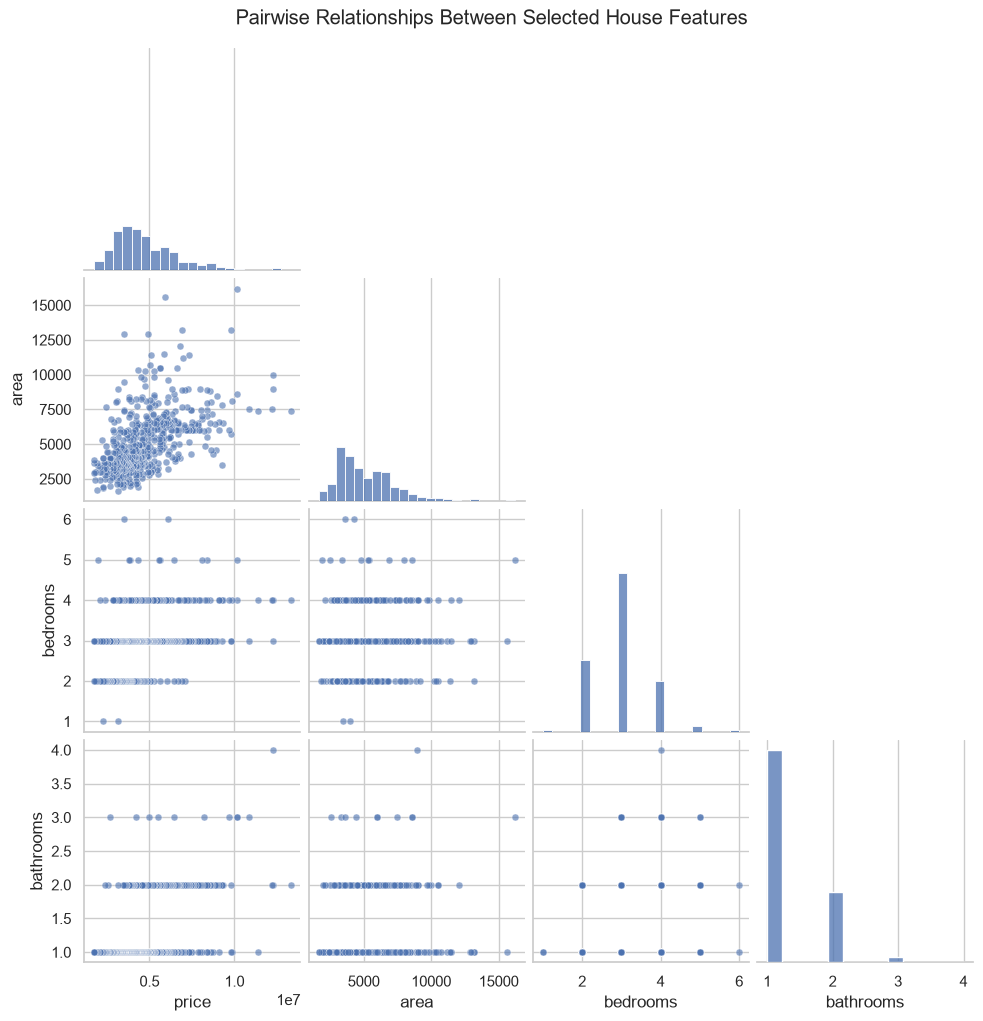

Features shown: ['price', 'area', 'bedrooms', 'bathrooms']
Saved: ..\outputs\visualizations\selected_numeric_features_pairplot.png


In [7]:
if len(selected_numeric_columns) < 2:
    raise ValueError("At least two numeric columns are required for a pair plot.")

pair_plot = sns.pairplot(
    data=houses[selected_numeric_columns],
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.6, "s": 25},
)
pair_plot.fig.suptitle("Pairwise Relationships Between Selected House Features", y=1.02)

pairplot_path = output_dir / "selected_numeric_features_pairplot.png"
pair_plot.fig.savefig(pairplot_path, dpi=150, bbox_inches="tight")
plot_files.append(pairplot_path)
plt.show()
plt.close(pair_plot.fig)
print("Features shown:", selected_numeric_columns)
print("Saved:", pairplot_path)

## Generated charts

The next cell confirms that each plot was saved under `outputs/visualizations/`. All visualizations use the original data; no chart preparation step alters the source CSV.

In [8]:
assert len(plot_files) == 6
assert all(path.exists() and path.stat().st_size > 0 for path in plot_files)

for path in plot_files:
    print(f"{path.name}: {path.stat().st_size:,} bytes")
print(f"\nSuccessfully generated {len(plot_files)} visualizations in {output_dir}.")

house_price_distribution_histogram.png: 55,225 bytes
house_area_vs_price_scatter.png: 94,936 bytes
numeric_features_correlation_heatmap.png: 80,007 bytes
house_price_boxplot.png: 31,154 bytes
average_price_by_preferred_area.png: 33,198 bytes
selected_numeric_features_pairplot.png: 160,669 bytes

Successfully generated 6 visualizations in ..\outputs\visualizations.
